# Applied Statistics

Solutions to the problems.

## ASSESSMENT NOTES [Here](https://github.com/ianmcloughlin/applied-statistics/blob/main/assessment.md)

Organization and Structure
Your submission should be in the main branch of your repository. Include a clear README.md, a suitable .gitignore file, and an accurate requirements.txt file. Avoid including unnecessary files or folders. Use lowercase file and folder names, except for the usual files like README.md. Do not use spaces or special characters in filenames. Underscores, hyphens, and full stops are okay.

Your commit history should show how your work evolved: improvements, refinements, and added clarity. Keep your notebook reproducible, clean, and concise. Use a level 1 heading for the notebook title. Use level 2 Markdown headings to clearly identify each problem within the notebook. Use Markdown cells to give explanations and insights into your code.

Follow Python coding standards and guidelines such as PEP8. Write clean, readable, and efficient code using meaningful variable names and consistent formatting. Break code into smaller, manageable cells whenever possible. Each code cell should focus on a single step in your overall solution. Include meaningful comments and docstrings in your code. You can use modules in the standard library and any of the packages in the requirements.txt file in this repository and their dependencies. Ask before using anything else.

# PREVIOUS IRIS ANALYSIS - DELETE LATER

https://github.com/KaiiMenai/pands-project/tree/main

https://github.com/KaiiMenai/poda-tasks/tree/main

# DELETE THIS LATER - HERE FOR REFERENCE

## Problems

Complete all problems below in your `problems.ipynb` notebook.
Your notebook should tell a story, using Markdown cells to explain your thinking and code cells to perform the technical tasks.
Your notebook must also run from top to bottom on a standard machine in three minutes or less.

### Problem 1: Exploring Petal Length

The [Iris dataset](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv) contains measurements of 150 iris flowers belonging to three species: `setosa`, `versicolor`, and `virginica`.
For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of `petal_length`.

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### Problem 2: Correlation Between Petal Length and Petal Width

Investigate the relationship between `petal_length` and `petal_width` in the Iris dataset.

1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
3. Calculate the Pearson correlation coefficient separately for each of the three species.
4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

### Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their `petal_length` and `petal_width`.

For each pair of species:

- `setosa` vs `versicolor`
- `setosa` vs `virginica`
- `versicolor` vs `virginica`

perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using `scipy.stats`.
3. Use a significance level of $\alpha=0.05$ to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

### Problem 4: Comparing the Species Using ANOVA

The t-tests in Problem 3 require several separate comparisons between species.
Instead, investigate differences in **petal length** and **petal width** using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using `scipy.stats`.
3. Report the F-statistic and p-value.
4. Use a significance level of $\alpha=0.05$ to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.


***

## Import the dataset into the notebook.

- explain steps.
- how to's
- the different ways to do it.
- maybe explain a little about the dataset - Versicolor, Setosa, Virginica

## Import the modules and data

libraries and packages to be used throughout.

In [24]:
# Import libraries that will help with visualising and analysing data. (Python. 2025. Built-in types. https://docs.python.org/3/library/stdtypes.html)
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as skl
from scipy.stats import f_oneway
from scipy.stats import norm
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Where can the data be found:

The iris data can be found on the UCI Machine Learning Repository, Iris Data Set webpage (https://archive.ics.uci.edu/dataset/53/iris). However, it is also readily available within Python. The iris data can be imported into python (or in this case the Jupyter notebook) via use of the skl learn function, or via use of a read_csv function. The load_iris() function here, is a custom (although commonly used function) that loads the iris dataframe into the current working environment from the sklearn.datasets library. (https://labex.io/tutorials/python-classifying-iris-using-svm-300195)

In [25]:
# Using the sklearn.datasets module to load the iris dataset
from sklearn.datasets import load_iris
load_iris = load_iris()
# Load the iris dataset into a pandas DataFrame 
iris_data = pd.DataFrame(data=load_iris.data, columns=load_iris.feature_names)

For the purposes of this notebook, moving forward, the data being used will be that imported from the following webpage: https://gist.github.com/curran/a08a1080b88344b0c8a7 .

The raw file for the .csv file was more easily imported and read by python using a source from https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html .

In [26]:
# This will load in the iris dataset from the web link.

df = pd.read_csv("https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv")

Image references for the species of Iris recorded in the dataset are displayed in figure 1.
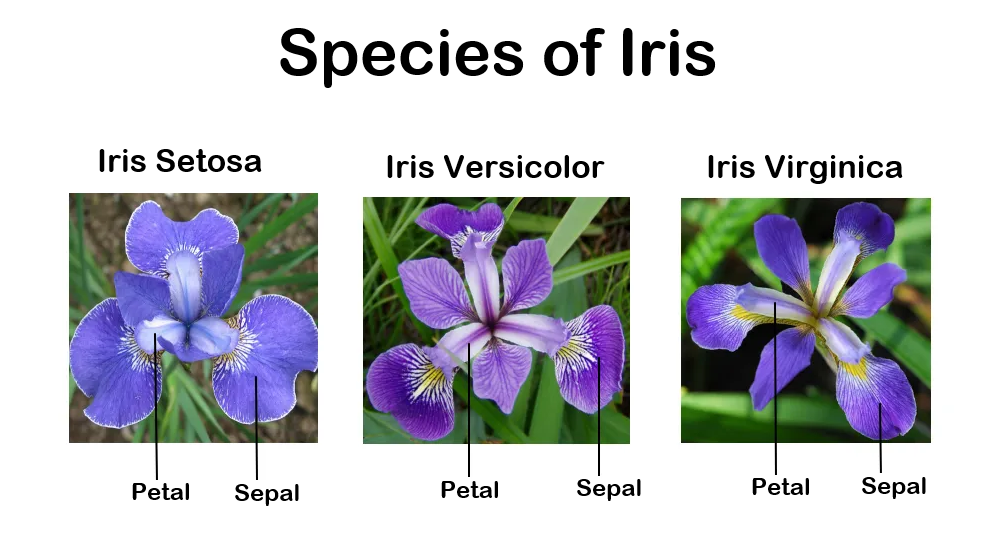
Figure 1 - Species of Iris in the dataset. (Source: https://3tw.medium.com/scikit-learn-the-iris-dataset-and-machine-learning-the-journey-to-a-new-skill-c8d2f537e087)

## Problem 1

The [Iris dataset](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv) contains measurements of 150 iris flowers belonging to three species: `setosa`, `versicolor`, and `virginica`.
For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of `petal_length`.

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

Investigate petal length

1. Histogram - petal lengths

Histograms were plotted for each of the features with the species colour coded (https://seaborn.pydata.org/generated/seaborn.scatterplot.html, https://www.geeksforgeeks.org/interpretations-of-histogram/) - change this to be for each species  

Select petal length data and group by species.

10 Smallest Petal Lengths
   species  petal_length
22  setosa           1.0
13  setosa           1.1
14  setosa           1.2
35  setosa           1.2
2   setosa           1.3
16  setosa           1.3
36  setosa           1.3
38  setosa           1.3
40  setosa           1.3
41  setosa           1.3

10 Largest Petal Lengths
       species  petal_length
118  virginica           6.9
117  virginica           6.7
122  virginica           6.7
105  virginica           6.6
131  virginica           6.4
107  virginica           6.3
109  virginica           6.1
130  virginica           6.1
135  virginica           6.1
100  virginica           6.0


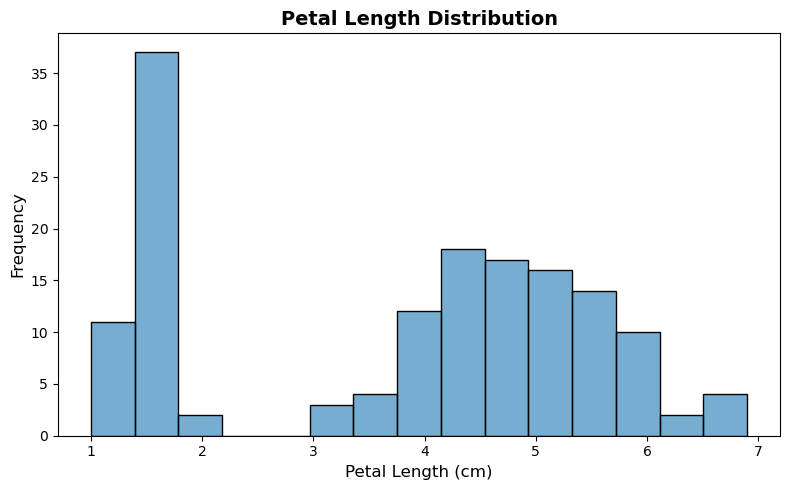

In [27]:
print("10 Smallest Petal Lengths")
print(df[['species', 'petal_length']].nsmallest(10, 'petal_length'))

print("\n10 Largest Petal Lengths")
print(df[['species', 'petal_length']].nlargest(10, 'petal_length'))

# Specify the single plot size.
plt.figure(figsize=(8, 5))

# Plot histogram for Petal Length
sns.histplot(data=df, x="petal_length", kde=False, bins=15, alpha=0.6)

#Adding the title to the histogram plot and labelling the axis. Also adding a legend to the plot for species differentiation. 
plt.title("Petal Length Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Petal Length (cm)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Clean up the layout and display the plot.
plt.tight_layout()
plt.show()

2. On Histogram superimpose appropriate normal distribution using mean and std. dev. if the data

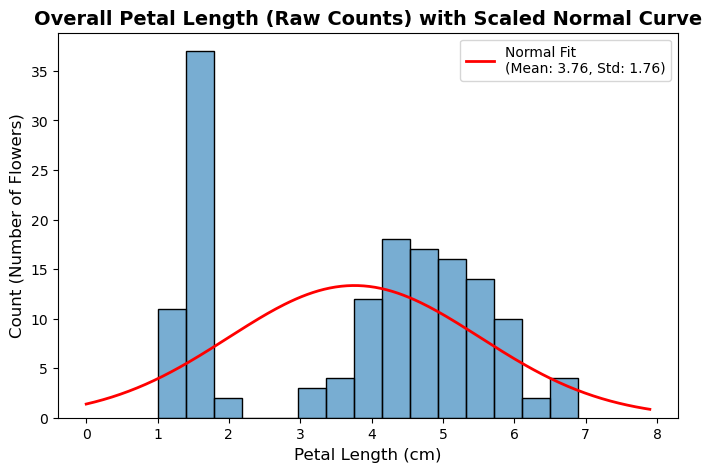

In [33]:
# 1. Use raw count histogram - This can be scaled to a density plot by multiplying the normal pdf by total count and bin width. Thus allowing the normal curve to be plotted over the histogram counts. But the histogram is still in raw counts, not density. This is important to note because the y-axis is in counts, not probability density. The normal curve will be scaled to match the histogram counts.
plt.figure(figsize=(8, 5))
ax = sns.histplot(data=df, x='petal_length', bins=15, kde=False, alpha=0.6)

# 2. Calculate the global mean and standard deviation (std. dev).
mean = df['petal_length'].mean()
std = df['petal_length'].std()

# 3. Calculate scaling factors to lift the line up to count levels - this ensures that the normal curve is scaled appropriately - otherwise it may end up as a flat line at the bottom of the histogram (as seen when I first tried to plot this).
total_count = len(df)
# Find the exact width of one histogram bin
bin_width = ax.patches[0].get_width()

# 4. Generate the curve points
x = np.linspace(df['petal_length'].min() - 1, df['petal_length'].max() + 1, 200)
# Multiply the normal PDF by total count and bin width
y = norm.pdf(x, mean, std) * total_count * bin_width

# 5. Plot the scaled line over your counts
plt.plot(x, y, color='red', linewidth=2, label=f'Normal Fit\n(Mean: {mean:.2f}, Std: {std:.2f})',)

# Titles and Labels
plt.title( 'Overall Petal Length (Raw Counts) with Scaled Normal Curve', fontsize=14, fontweight='bold',)
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Count (Number of Flowers)', fontsize=12)
plt.legend()

plt.show()

Interesting point to note about the length data is that although the normal distribution, looks normal, the data itself is bimodal (two seperate peaks). This is due to the setosa data (previously plotted [here](https://github.com/KaiiMenai/poda-tasks/blob/main/tasks.ipynb)), as the setosa species displays consistently shorter petal lengths than the other two species (virginica, versicolor).

3. Separate histograms for the 3 species and superimpose appropriate normal dist. on each.

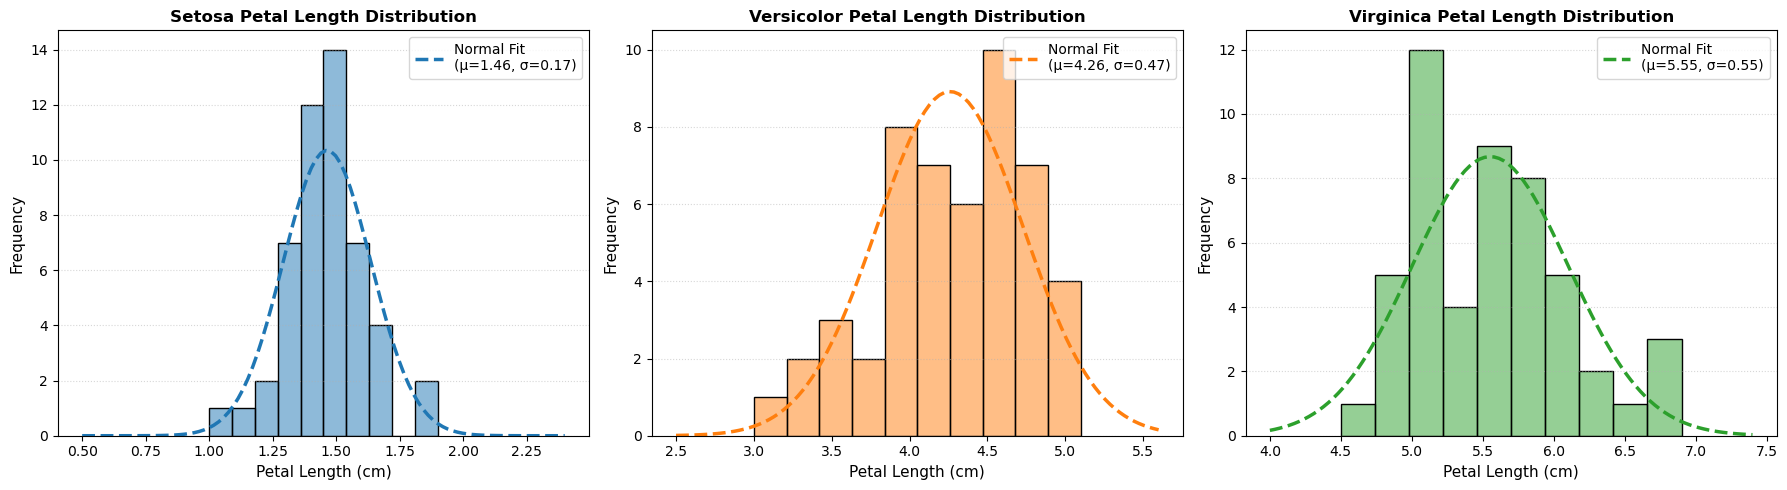

In [ ]:
# Group data by species
setosa = df[df['species'] == 'setosa']['petal_length']
versicolor = df[df['species'] == 'versicolor']['petal_length']
virginica = df[df['species'] == 'virginica']['petal_length']

# 1. Set up a 1x3 horizontal layout grid (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 2. Match the pre-grouped variables with their titles, colors, and assigned subplot index
species_groups = [
    (setosa, 'Setosa', '#1f77b4', 0),      # Index 0 = Left plot
    (versicolor, 'Versicolor', '#ff7f0e', 1),  # Index 1 = Middle plot
    (virginica, 'Virginica', '#2ca02c', 2),    # Index 2 = Right plot
]

# 3. Loop through the subsets to build each plot independently
for data, name, color, ax_idx in species_groups:
  # Target the specific subplot axis (don't want the data being plotted on the wrong subplot).
  ax = axes[ax_idx]
  
  # Filter the main dataframe to only plot this specific species histogram
  sns.histplot( data=df[df['species'] == name.lower()], x='petal_length', kde=False, 
      bins=10,        # Reduced bins slightly since data is split
      color=color, alpha=0.5, ax=ax, edgecolor='black')
  
  # Extract the exact bin width for this specific subplot (used for scaling the normal distribution curve to match the individual histogram counts).
  bin_width = ax.patches[0].get_width() if ax.patches else 0.1
  
  # Calculate normal distribution parameters directly from your variables
  mu = data.mean() # signifies the mean of the data
  sigma = data.std() # signifies the standard deviation of the data
  count = len(data)
  
  # Generate continuous x-axis grid matching this specific species range
  x = np.linspace(data.min() - 0.5, data.max() + 0.5, 100)
  
  # Scale the mathematical curve to match raw frequency counts
  y = norm.pdf(x, mu, sigma) * count * bin_width
  
  # Overlay the scaled normal curve on the active subplot axis.
  ax.plot( x, y, color=color, linewidth=2.5, linestyle='--', label=f'Normal Fit\n(μ={mu:.2f}, σ={sigma:.2f})')
  
  # Specific subplot titles, labels, and legend placement.
  ax.set_title(f'{name} Petal Length Distribution', fontsize=12, fontweight='bold')
  ax.set_xlabel('Petal Length (cm)', fontsize=11)
  ax.set_ylabel('Frequency', fontsize=11)
  ax.legend(loc='upper right', fontsize=10)
  ax.grid(axis='y', linestyle=':', alpha=0.5)

# Adjust layout for side-by-side spacing and display
plt.tight_layout()
plt.show()

4. Mean and std. dev of petal length for complete dataset for each species.

5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

## Problem 2

Correlation Between Petal Length and Petal Width
Investigate the relationship between petal_length and petal_width in the Iris dataset.

1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers. [How To](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) [And Here](https://www.geeksforgeeks.org/data-science/pearson-correlation-in-data-science/) - to do it convert datafframe into series (i.e. length, width) then compare using pearsonr - only looking to see if length and width sre correlated, not species.

2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship. - could use numpy

3. Calculate the Pearson correlation coefficient separately for each of the three species. - dame as before but do it within each species

4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

## Problem 3

Comparing Species Using t-Tests

Investigate whether the three iris species differ in their `petal_length` and `petal_width`.

For each pair of species:

- `setosa` vs `versicolor`
- `setosa` vs `virginica`
- `versicolor` vs `virginica`

perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using `scipy.stats`.
3. Use a significance level of $\alpha=0.05$ to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

## Problem 4

The t-tests in Problem 3 require several separate comparisons between species.
Instead, investigate differences in **petal length** and **petal width** using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using `scipy.stats`.
3. Report the F-statistic and p-value.
4. Use a significance level of $\alpha=0.05$ to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups. [REF](https://pmc.ncbi.nlm.nih.gov/articles/PMC3916511/) [REF2](https://wisc.pb.unizin.org/biocorestatistics/chapter/statistical-inference-comparing-more-than-2-groups/) [REF3](https://www.statisticssolutions.com/free-resources/directory-of-statistical-analyses/anova/)


# For each variable: - ANOVA HERE - https://github.com/KaiiMenai/poda-tasks/blob/main/tasks.ipynb

1. State the null and alternative hypotheses for a one-way ANOVA.


2. Perform a one-way ANOVA comparing the three species using `scipy.stats`.

3. Report the F-statistic and p-value.

4. Use a significance level of $\alpha=0.05$ to determine whether there is evidence that the species have different population means.

5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

## SUMMARY OF RESULTS

# END